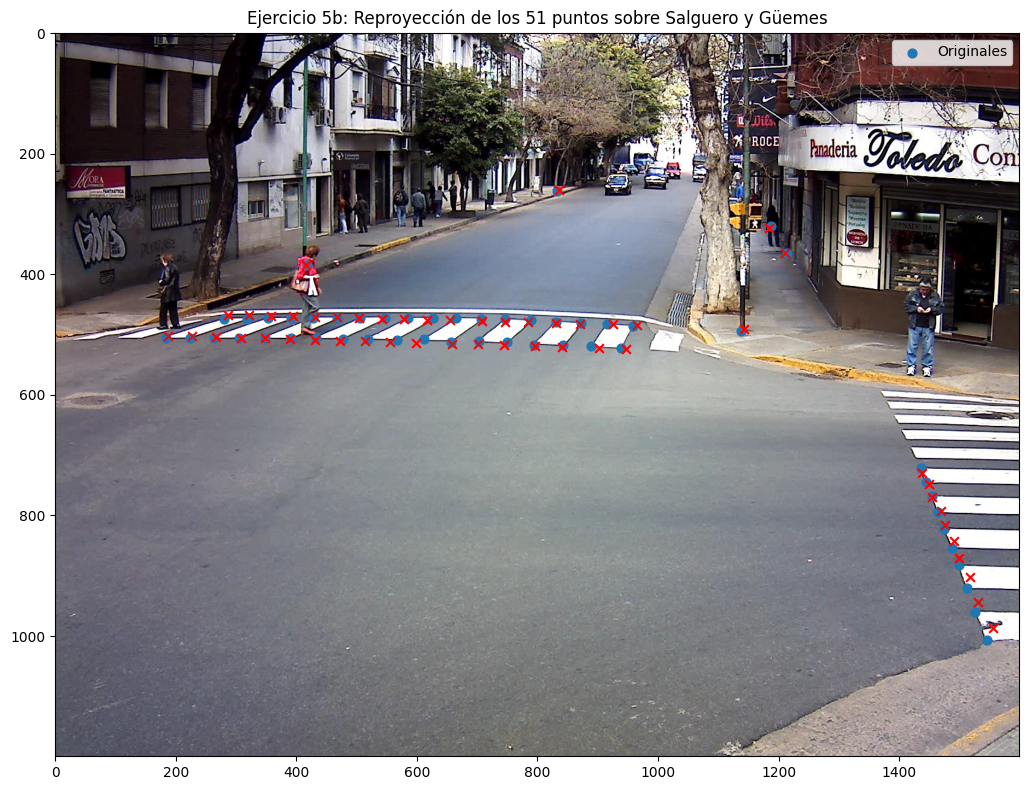

In [1]:
import alc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd

Para generar el txt con los puntos extraidos de las imagenes del item 3

In [15]:
import cv2
import numpy as np

puntos_totales = []

# Iterar sobre las 20 imágenes del tablero
for i in range(1, 21):
    ruta = f' calib/coplanar/Im_R_{i}.png'
    img = cv2.imread(ruta)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    encontrado, esquinas = cv2.findChessboardCorners(gray, (11, 7), None)

    if encontrado:
        puntos_totales.append(esquinas.reshape(-1, 2))

# una sola matriz de 1540 filas (20 imágenes * 77 puntos) x 2 columnas
matriz_puntos = np.vstack(puntos_totales)

np.savetxt('mis_puntos_extraidos.txt', matriz_puntos, delimiter=',')

Archivo 'mis_puntos_extraidos.txt' generado con éxito.


**Ejercicio 2 - Calibración con puntos 3D**

a)

In [10]:
todosLosPuntos2D = np.loadtxt(' calib/3d/detected_corners.txt')
puntos3D = np.loadtxt(' calib/3d/p_W_corners.txt', delimiter=',')

# Extraemos solo la primera fila (correspondiente a img_0001.jpg)
# y la redimensionamos a una matriz de 12 filas x 2 columnas (u, v)
puntos2D = todosLosPuntos2D[0].reshape(12, 2)

Q = alc.obtenerQ3d(puntos2D, puntos3D)

M = alc.resolverDLT3D(Q)

R, t, K = alc.devolverMatricesCalibracion3d(M)

# Mostrar resultados
print("Matriz de Proyección M:\n", M)
print("\nMatriz de Rotación R:\n", R)
print("\nVector de Traslación t:\n", t)
print("\nMatriz de Parámetros Intrínsecos K:\n", K)

Matriz de Proyección M:
 [[-6.44865266e-02 -2.27816085e-02  1.39906512e-02 -8.37825121e-01]
 [-3.69903840e-03 -6.10180404e-02 -1.31187333e-02 -5.37810986e-01]
 [-8.83537006e-05 -4.47215928e-05 -7.79036987e-05 -5.11440314e-03]]

Matriz de Rotación R:
 [[-0.618213   -0.12921397  0.77531699]
 [ 0.35508353 -0.92591643  0.12881947]
 [-0.70123346 -0.35494017 -0.61829533]]

Vector de Traslación t:
 [[ 18.16793831]
 [ 14.50326886]
 [-40.59128918]]

Matriz de Parámetros Intrínsecos K:
 [[ 4.25859862e+02 -1.56351856e-02  3.54418499e+02]
 [ 0.00000000e+00  4.24565307e+02  2.56853355e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


b)

In [29]:
_,_, K_rest = alc.devolverMatricesCalibracion3d(M,restriccion=True)
print("\nMatriz de Parámetros Intrínsecos K con αu = αv y K12 = 0.:\n", K_rest)


Matriz de Parámetros Intrínsecos K con αu = αv y K12 = 0.:
 [[425.21258467   0.         354.41849869]
 [  0.         425.21258467 256.85335534]
 [  0.           0.           1.        ]]


**Ejercicio 3 - Calibración con puntos coplanares**

a) Por Teorema de la Dimensión: $Rg(Q) + dim(Nu(Q)) = 9$. Para que el sistema homogéneo $Q*h = 0$ tenga una solución no nula única salvo por un factor de escala, el núcleo de $Q$ debe tener dimensión 1. Por lo tanto, $Rg(Q) = 9 - 1 = 8$. La matriz $Q$ debe tener rango 8. Lo cual requiere que mínimo $n = 4$


In [32]:
#Puntos en las imagenes
todos_los_puntos_2d = np.loadtxt('mis_puntos_extraidos.txt', delimiter=',')
imgPts_todas = todos_los_puntos_2d.reshape(20, 77, 2)

#Puntos del tablero
objPts = np.zeros((77, 3))
k = 0
for j in range(7):
    for i in range(11):
        objPts[k, 0] = 30 * i
        objPts[k, 1] = 30 * j
        k += 1

Hlst = []

# Para cada una de las 20 vistas
for j in range(20):

    imgPts_actual = imgPts_todas[j]
    H_actual = alc.resolverHomografia(objPts, imgPts_actual)
    Hlst.append(H_actual)


# Imprimimos la primera homografía calculada (H_1)
print("Matriz de Homografía H (primera imagen):")
print(np.round(Hlst[0], 4))

A=alc.armarA(Hlst)
print("\nDimension de A:")
print(A.shape)

K=alc.calcularMatrizK2D(A)
print("\nMatriz K:")
print(K)

r1,t1=alc.obtenerPose2D(K,Hlst[0])
print("\nDe la primera imagen:")
print("R1:\n",np.round(r1,4))
print("t1:\n",np.round(t1,4))

Matriz de Homografía H (primera imagen):
[[ 1.379600e+00 -2.660000e-02  3.726671e+02]
 [ 3.160000e-02  1.369300e+00  1.042765e+02]
 [ 1.000000e-04 -0.000000e+00  1.000000e+00]]

Dimension de A:
(40, 6)

Matriz K:
[[743.33332466  -0.91231188 519.76608306]
 [  0.         754.50705995 298.47729979]
 [  0.           0.           1.        ]]

De la primera imagen:
R1:
 [[ 9.999e-01 -1.440e-02 -1.000e-04]
 [ 1.440e-02  9.999e-01  0.000e+00]
 [ 1.000e-04 -0.000e+00  1.000e+00]]
t1:
 [[0.2019]
 [0.2555]
 [0.0018]]
